# PortfolioPilot - Milestone 4: baseline models

This notebook only **runs and displays** the M4 results. All the code lives in `src/portfolio_pilot`
(`models/`, `evaluate.py`, `dataset.py`, `run_baselines.py`), and every setting is in `config.yaml`.

The same results come from one command at the repository root:

```
python -m portfolio_pilot.run_baselines
```

The test set is never loaded (`evaluation.use_test: false` in `config.yaml`).

## Step 1 - Set up

In [3]:
import os, sys
from pathlib import Path

ROOT = Path(r"C:\Users\Ivory\Portfolio-Pilot-repo\Portfolio-Pilot")   # your project folder

os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
print("Project folder:", ROOT, "| config.yaml found:", (ROOT / "config.yaml").exists())

Project folder: C:\Users\Ivory\Portfolio-Pilot-repo\Portfolio-Pilot | config.yaml found: True


## Step 2 - Run every model (the same command as in the README)
Rebuilds the M3 data from the raw SCF file, fits the reference, the rule and the baselines, cross-validates on the training households and scores them on the validation households.

In [5]:
from portfolio_pilot import run_baselines
run_baselines.main()

Building data (clean -> split -> features -> archetypes) ...


c:\Users\Ivory\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Ivory\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\Ivory\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Ivory\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Training households: 3052 | validation households: 654 | test set loaded: False
k-NN search: [{'k': 5, 'val_macro_f1': 0.834}, {'k': 15, 'val_macro_f1': 0.844}, {'k': 25, 'val_macro_f1': 0.83}] -> k = 15
  Reference: majority class        train F1 0.089 | CV F1 0.085 ± 0.005 | val F1 0.088
  Rule: questionnaire score        train F1 0.128 | CV F1 0.127 ± 0.014 | val F1 0.103
  Nearest centroid                 train F1 0.806 | CV F1 0.802 ± 0.026 | val F1 0.801
  Logistic regression              train F1 0.841 | CV F1 0.833 ± 0.029 | val F1 0.850
  k-NN (k=15)                      train F1 0.835 | CV F1 0.811 ± 0.019 | val F1 0.844
Saved results to C:\Users\Ivory\Portfolio-Pilot-repo\Portfolio-Pilot\results


## Step 3 - Results table (Table 1 of the report)

In [6]:
import pandas as pd
from IPython.display import Image, display

R = ROOT / "results"
pd.read_csv(R / "m4_results_table.csv")

,Model,"Macro F1, training","Macro F1, 5-fold CV (mean ± SD)","Macro F1, validation","Severe over-risk, validation","Within one archetype, validation",Meets criterion
0,Reference: majority class,0.089,0.085 ± 0.005,0.088,0.0%,48.6%,No
1,Rule: questionnaire score,0.128,0.127 ± 0.014,0.103,5.6%,62.8%,No
2,Nearest centroid,0.806,0.802 ± 0.026,0.801,0.0%,96.5%,Yes
3,Logistic regression,0.841,0.833 ± 0.029,0.850,0.0%,96.9%,Yes
4,k-NN (k=15),0.835,0.811 ± 0.019,0.844,0.0%,96.7%,Yes


## Step 4 - Supporting results

In [7]:
print("k-NN settings tried on the validation set")
display(pd.read_csv(R / "m4_knn_k_search.csv").round(3))

print("Cross-validation repeated with other fold seeds")
display(pd.read_csv(R / "m4_cv_seed_check.csv").round(3))

print("Validation macro F1 on implicates 2-5")
display(pd.read_csv(R / "m4_implicates.csv").pivot(index="model", columns="implicate", values="val_macro_f1").round(3))

print("Validation F1 for each archetype")
display(pd.read_csv(R / "m4_per_class_f1.csv").round(3))

k-NN settings tried on the validation set


,k,val_macro_f1,val_accuracy,val_within_one,val_over_risk,val_severe_over_risk
0,5,0.834,0.800,0.963,0.097,0.008
1,15,0.844,0.811,0.967,0.085,0.000
2,25,0.830,0.801,0.968,0.099,0.000


Cross-validation repeated with other fold seeds


,model,cv_seed,cv_macro_f1_mean,cv_macro_f1_sd
0,Reference: majority class,7275,0.085,0.005
1,Reference: majority class,11,0.089,0.003
2,Reference: majority class,23,0.086,0.001
3,Rule: questionnaire score,7275,0.127,0.014
4,Rule: questionnaire score,11,0.128,0.016
5,Rule: questionnaire score,23,0.127,0.012
6,Nearest centroid,7275,0.802,0.026
7,Nearest centroid,11,0.802,0.027
8,Nearest centroid,23,0.801,0.006
9,Logistic regression,7275,0.833,0.029


Validation macro F1 on implicates 2-5


implicate,2,3,4,5
model,,,,
Logistic regression,0.839,0.834,0.844,0.839
Nearest centroid,0.787,0.806,0.792,0.793
Reference: majority class,0.085,0.090,0.084,0.086
Rule: questionnaire score,0.122,0.119,0.104,0.121
k-NN (k=15),0.833,0.839,0.843,0.844


Validation F1 for each archetype


,model,A0,A1,A2,A3,A4
0,Reference: majority class,0.000,0.438,0.000,0.000,0.000
1,Rule: questionnaire score,0.041,0.254,0.031,0.169,0.018
2,Nearest centroid,0.978,0.923,0.934,0.456,0.715
3,Logistic regression,0.992,0.945,0.998,0.558,0.757
4,k-NN (k=15),1.000,0.945,0.997,0.547,0.730


## Step 5 - Figures

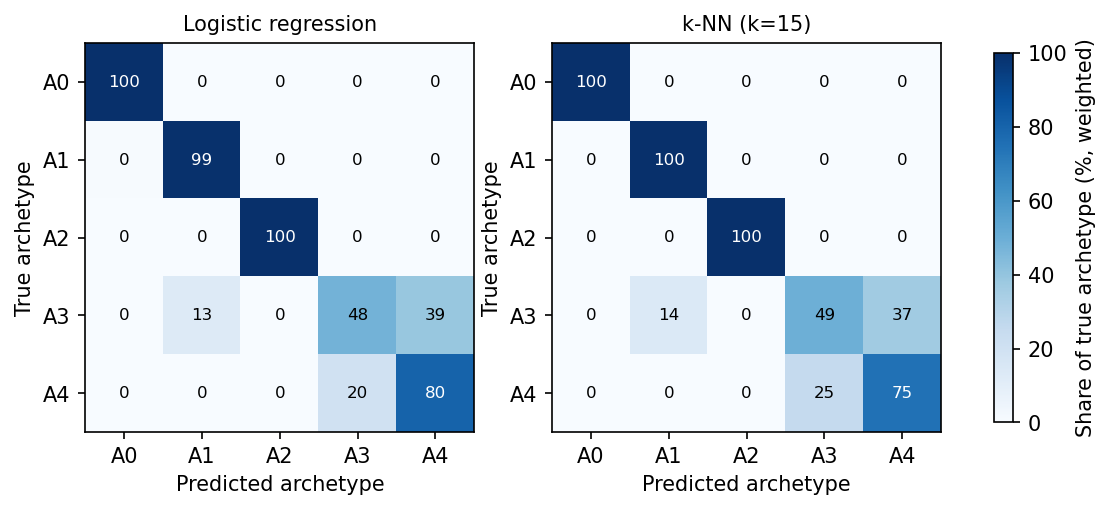

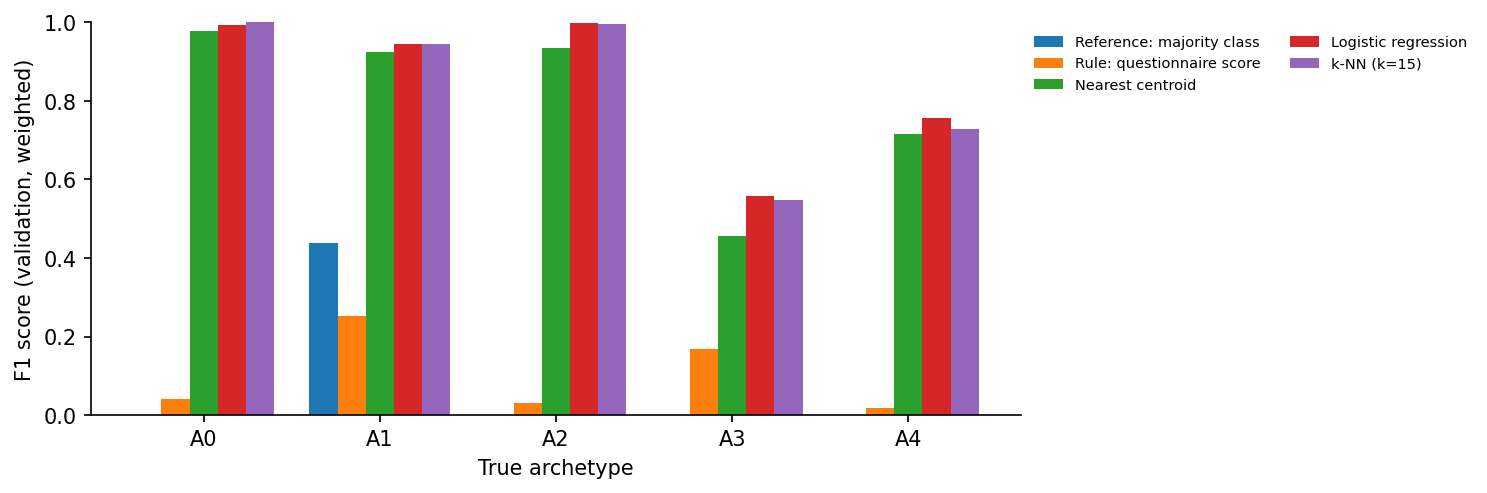

In [8]:
display(Image(filename=str(R / "figures" / "m4_fig1_confusion_matrices.png")))
display(Image(filename=str(R / "figures" / "m4_fig2_per_class_f1.png")))